<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/07_cLab_TcEstudiante.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Laboratorio — Determinación de la temperatura crítica del modelo de Ising 2D con redes neuronales de *scikit-learn*

**Maestría en Computación Científica · Módulo de Redes Neuronales · Modelo de Ising 2D**

En este laboratorio vas a **entrenar una red neuronal clasificadora con `scikit-learn`** y a
usarla como un *termómetro* para localizar la **temperatura crítica** $T_c$ de la transición
de fase ferromagnética del modelo de Ising en 2D.



## Objetivos de aprendizaje

Al terminar este laboratorio serás capaz de:

1. Entrenar un clasificador de red neuronal con `sklearn.neural_network.MLPClassifier`,
   identificando el papel de cada hiperparámetro.
2. **Contrastar la API de `scikit-learn` 
3. Usar un clasificador entrenado **lejos** de la transición para estimar la fase
   (ordenada / desordenada) a temperaturas **cercanas** a $T_c$.
4. Estimar $T_c$ a partir del cruce $\langle P(y{=}1\mid X)\rangle = 0.5$, cuantificar su
   incertidumbre entre realizaciones y compararla con el valor exacto de Onsager.

## 1. Física: transición de fase del modelo de Ising 2D

El modelo de Ising 2D en una red $L\times L$ con acoplamiento ferromagnético $J>0$ tiene energía

$$E(\{s\}) = -J \sum_{\langle i,j\rangle} s_i\, s_j, \qquad s_i \in \{-1, +1\},$$

donde la suma es sobre pares de primeros vecinos. En unidades $J = k_B = 1$, el sistema infinito
presenta una transición de fase de segundo orden a la **temperatura crítica de Onsager**

$$T_c = \frac{2}{\ln\!\left(1+\sqrt{2}\right)} \approx 2.269.$$

- $T < T_c$: **fase ordenada** (ferromagnética), magnetización por sitio $|m|$ grande.
- $T > T_c$: **fase desordenada** (paramagnética), $|m|\approx 0$.

**Idea del laboratorio** (Carrasquilla & Melko, *Nature Physics* **13**, 431 (2017)): un
clasificador entrenado solo con configuraciones *claramente* ordenadas ($y=0$) y *claramente*
desordenadas ($y=1$) aprende una frontera de decisión que, evaluada en configuraciones cercanas
a $T_c$, se comporta como un **parámetro de orden efectivo**. La temperatura donde
$\langle P(y{=}1\mid X)\rangle = 0.5$ estima $T_c$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RNG = 42
np.random.seed(RNG)

## 3. Datos: configuraciones lejos de $T_c$

`ising_dataset.npz` contiene configuraciones de espines de una red $16\times 16$ con frontera
periódica, generadas por Monte Carlo (Metrópolis). Campos:

| Campo | Forma | Significado |
|---|---|---|
| `X` | `(1600, 16, 16)` | Configuraciones de espines $s_i \in \{-1,+1\}$ |
| `y` | `(1600,)` | Etiqueta de fase: `0` = ordenada ($T$ baja), `1` = desordenada ($T$ alta) |
| `T` | `(1600,)` | Temperatura de cada configuración |
| `m` | `(1600,)` | Magnetización por sitio $|m|$ |
| `realizacion` | `(1600,)` | Índice de cadena Monte Carlo independiente (`0..3`) |
| `Tc`, `L`, `frontera` | escalares | Metadatos ($T_c$ exacto, tamaño, tipo de frontera) |

Las temperaturas de entrenamiento **evitan** la región crítica: hay un hueco entre
$T=1.9$ y $T=2.6$.

In [2]:
datos = np.load("Datos/ising_dataset.npz", allow_pickle=False)
X = datos["X"]
y = datos["y"]
T = datos["T"]
m = datos["m"]
realizacion = datos["realizacion"]

Tc_exacto = float(datos["Tc"])
L = int(datos["L"])

print("X:", X.shape, X.dtype)
print("y:", y.shape, "->", np.unique(y, return_counts=True))
print("realizaciones:", np.unique(realizacion))
print("Tc exacto (Onsager):", Tc_exacto)

X: (1600, 16, 16) int8
y: (1600,) -> (array([0, 1], dtype=int8), array([800, 800]))
realizaciones: [0 1 2 3]
Tc exacto (Onsager): 2.269185314213022


### Ejercicio 1 — Exploración

Responde con código y en una celda de texto:

1. ¿Qué temperaturas tienen etiqueta `y = 0` y cuáles `y = 1`? ¿Dónde está el "hueco"?
2. ¿Está balanceado el problema (cuántas configuraciones por clase)?
3. Grafica el histograma de $|m|$ separando por clase. ¿Se separan bien las dos fases?

y        0    1
T              
1.200  160    0
1.375  160    0
1.550  160    0
1.725  160    0
1.900  160    0
2.600    0  160
2.825    0  160
3.050    0  160
3.275    0  160
3.500    0  160


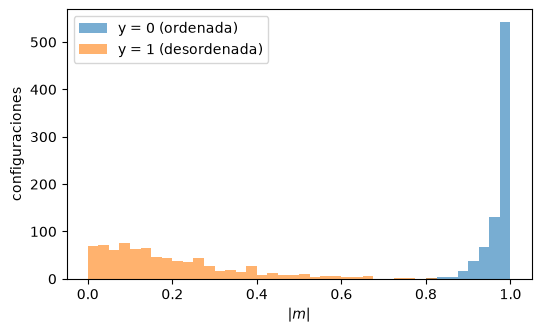

In [3]:
# --- Ejercicio 1 ---
print(pd.crosstab(T, y, rownames=["T"], colnames=["y"]))

plt.figure(figsize=(6, 3.5))
for cls, nombre in [(0, "ordenada"), (1, "desordenada")]:
    plt.hist(m[y == cls], bins=40, range=(0, 1), alpha=0.6, label=f"y = {cls} ({nombre})")
plt.xlabel("$|m|$")
plt.ylabel("configuraciones")
plt.legend()
plt.show()

1. Las temperaturas $T\in\{1.2,\,1.375,\,1.55,\,1.725,\,1.9\}$ tienen `y = 0` y las temperaturas $T\in\{2.6,\,2.825,\,3.05,\,3.275,\,3.5\}$ tienen `y = 1`. El hueco queda en $(1.9,\,2.6)$, justo alrededor de $T_c\approx2.269$.
2. Sí, hay 800 configuraciones por clase (160 por temperatura).
3. Sí. En la fase ordenada $|m|\ge0.81$ y en la desordenada $|m|\le0.80$, por lo que los histogramas no se solapan, aunque la cola de $T=2.6$ llega casi hasta la fase ordenada.

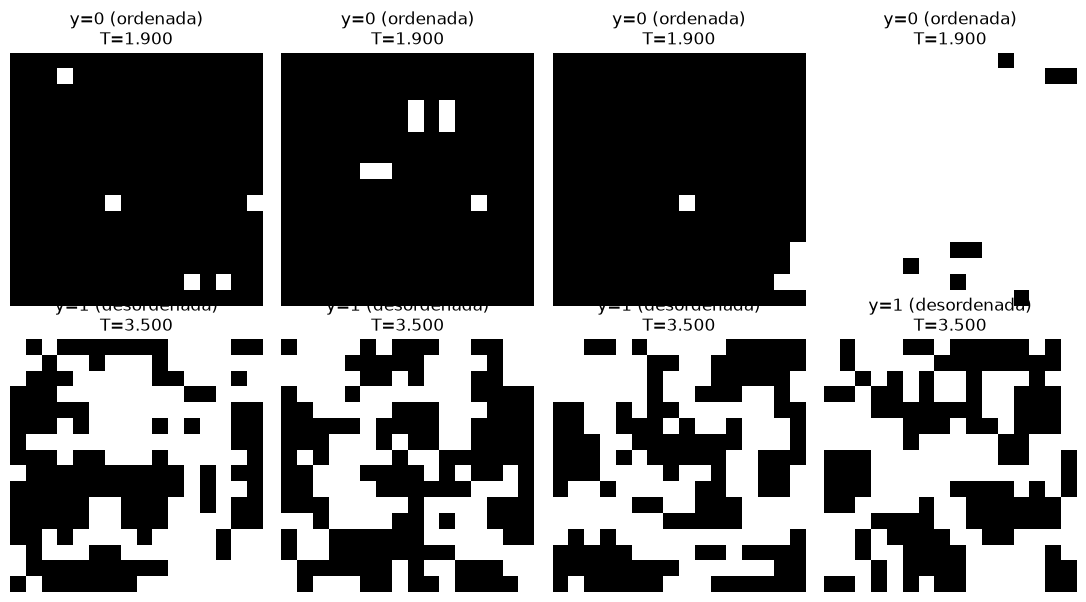

In [4]:
# Configuraciones típicas a T baja y T alta
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for row, (cls, titulo) in enumerate([(0, "ordenada"), (1, "desordenada")]):
    idx = np.where(y == cls)[0][:4]
    for k, i in enumerate(idx):
        axes[row, k].imshow(X[i], cmap="gray", vmin=-1, vmax=1)
        axes[row, k].set_title(f"y={cls} ({titulo})\nT={T[i]:.3f}")
        axes[row, k].axis("off")
plt.tight_layout()
plt.show()

## 4. Partición de los datos: por **realización**

Las configuraciones de una misma cadena Monte Carlo (`realizacion`) están **correlacionadas**
temporalmente. Si mezcláramos al azar, configuraciones casi idénticas caerían en *train* y en
*test* a la vez → fuga de información y métricas infladas.

Partimos por realización:

- **Entrenamiento:** realizaciones `0` y `1`
- **Validación:** realización `2`
- **Prueba:** realización `3`

Además aplanamos cada configuración $16\times16 \to 256$ porque `MLPClassifier` espera
vectores de características.

### Ejercicio 2 — Construir los conjuntos

Completa las máscaras y los arreglos aplanados. Deberías obtener
`X_train (800, 256)`, `X_val (400, 256)` y `X_test (400, 256)`.

In [5]:
# --- Ejercicio 2  ---
mask_train = np.isin(realizacion, [0, 1])
mask_val   = realizacion == 2
mask_test  = realizacion == 3

def aplanar(A):
    return A.reshape(A.shape[0], L * L)

X_train, y_train, T_train = aplanar(X[mask_train]), y[mask_train], T[mask_train]
X_val,   y_val,   T_val   = aplanar(X[mask_val]),   y[mask_val],   T[mask_val]
X_test,  y_test,  T_test  = aplanar(X[mask_test]),  y[mask_test],  T[mask_test]

for nombre, Xs, ys in [("train", X_train, y_train),
                       ("val",   X_val,   y_val),
                       ("test",  X_test,  y_test)]:
    print(f"{nombre:5s}  X={Xs.shape}  y={ys.shape}  clases={np.bincount(ys)}")

train  X=(800, 256)  y=(800,)  clases=[400 400]
val    X=(400, 256)  y=(400,)  clases=[200 200]
test   X=(400, 256)  y=(400,)  clases=[200 200]


## 5. Entrenar el `MLPClassifier`

| Argumento | Valor | Qué controla |
|---|---|---|
| `hidden_layer_sizes=(16, 8, 4)` | 3 capas ocultas | Arquitectura: 256 → 16 → 8 → 4 → 2 |
| `activation="relu"` | ReLU | No linealidad de las capas ocultas |
| `solver="adam"` | Adam | Optimizador basado en gradiente estocástico |
| `learning_rate_init=0.001` | 0.001 | Tamaño de paso inicial |
| `max_iter=1000` | 1000 | Máximo de épocas (puede parar antes por tolerancia) |
| `random_state=42` | 42 | Reproducibilidad (init de pesos y *shuffling*) |

> La capa de salida (2 neuronas, *softmax*) y la pérdida (*log-loss*) las añade `scikit-learn`
> automáticamente al ver que `y` tiene dos clases enteras. En `NN_Cero.ipynb` esto era la
> `sigmoide` final + `cost_Function`; en PyTorch era `nn.Linear(..., 1)` + `BCEWithLogitsLoss`.

### Ejercicio 3 — Instanciar, entrenar y evaluar

1. Crea el modelo con los hiperparámetros de la tabla y ajústalo con `X_train, y_train`.
2. Reporta *accuracy* en train / val / test con `.score(...)`.
3. Grafica `model.loss_curve_` (la pérdida por época que `scikit-learn` guarda).

iteraciones: 675   log-loss final: 0.0453
accuracy train: 1.0000
accuracy val  : 0.9850
accuracy test : 0.9875


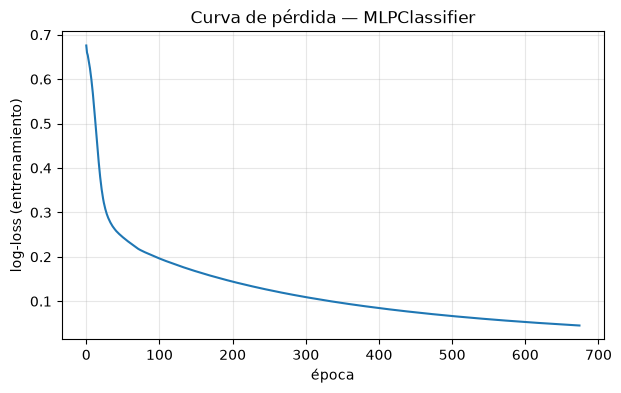

In [6]:
# --- Ejercicio 3  ---
model = MLPClassifier(
    hidden_layer_sizes=(16, 8, 4),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=RNG,
)
model.fit(X_train, y_train)

acc = {
    "train": model.score(X_train, y_train),
    "val":   model.score(X_val,   y_val),
    "test":  model.score(X_test,  y_test),
}
print(f"iteraciones: {model.n_iter_}   log-loss final: {model.loss_:.4f}")
for k, v in acc.items():
    print(f"accuracy {k:5s}: {v:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(model.loss_curve_)
plt.xlabel("época")
plt.ylabel("log-loss (entrenamiento)")
plt.title("Curva de pérdida — MLPClassifier")
plt.grid(alpha=0.3)
plt.show()

### Reflexión (sección 5)

- El *accuracy* de entrenamiento suele ser `1.0000`. ¿Es esto sobreajuste preocupante, dado que
  train / val / test dan valores parecidos? ¿Por qué este problema es "fácil" **lejos** de $T_c$?
- ¿Qué esperas que ocurra con las probabilidades del modelo **cerca** de $T_c$, donde no vio datos?

El 1.0 en entrenamiento no es un sobreajuste preocupante, porque validación y prueba, que usan realizaciones independientes, dan casi la misma accuracy. Lejos de $T_c$ el problema es fácil porque las dos fases difieren en $|m|$ de forma casi binaria, y basta una frontera simple para separarlas.

Cerca de $T_c$, donde el modelo no vio datos, se espera que las probabilidades tomen valores intermedios y pasen poco a poco de 0 a 1 a medida que aumenta $T$.

## 6. El clasificador como termómetro

Para una configuración $X$, `model.predict_proba(X)[:, 1]` es $P(y{=}1\mid X)$: la "confianza"
del modelo en que la configuración pertenece a la **fase desordenada**.

Promediando sobre muchas configuraciones a temperatura fija $T$ obtenemos una curva
$\langle P(y{=}1\mid X)\rangle(T)$ que va de $\approx 0$ (ordenado) a $\approx 1$ (desordenado).
Definimos la estimación de $T_c$ como la temperatura del **cruce por 0.5**.

## 7. Datos de barrido fino alrededor de $T_c$

`temperatura_critica.npz` contiene **6200** configuraciones $16\times16$ en **31 temperaturas**
entre 1.6 y 3.2 (más densas cerca de $T_c$), con 4 realizaciones. **No trae etiquetas de
entrenamiento:** solo `y_ref`, una etiqueta obtenida aplicando el $T_c$ exacto, que usaremos
**únicamente para verificar** (usarla para entrenar sería hacer trampa).

In [7]:
datos_tc = np.load("Datos/temperatura_critica.npz", allow_pickle=False)
X_tc = datos_tc["X"].reshape(datos_tc["X"].shape[0], L * L)
T_tc = datos_tc["T"]
realizacion_tc = datos_tc["realizacion"]
y_ref_tc = datos_tc["y_ref"]

print("X_tc:", X_tc.shape)
print("temperaturas:", np.unique(T_tc))

# Probabilidad de la clase "desordenada" (y = 1)
idx1 = list(model.classes_).index(1)
p1_tc = model.predict_proba(X_tc)[:, idx1]

# Chequeo con y_ref (NO usar para entrenar)
pred_tc = (p1_tc >= 0.5).astype(int)
print("accuracy vs y_ref (solo verificacion):",
      round((pred_tc == y_ref_tc).mean(), 4))

X_tc: (6200, 256)
temperaturas: [1.6   1.7   1.8   1.9   2.    2.05  2.075 2.1   2.125 2.15  2.175 2.2
 2.225 2.25  2.275 2.3   2.325 2.35  2.375 2.4   2.425 2.45  2.475 2.5
 2.6   2.7   2.8   2.9   3.    3.1   3.2  ]
accuracy vs y_ref (solo verificacion): 0.8247


### Ejercicio 4 — Curva $\langle P\rangle$ vs $T$

Construye un `DataFrame` con columnas `T, realizacion, prob` y agrégalo por
`(realizacion, T)` para obtener la media y la desviación de `prob`. Grafica una curva por
realización y marca la línea $P = 0.5$.

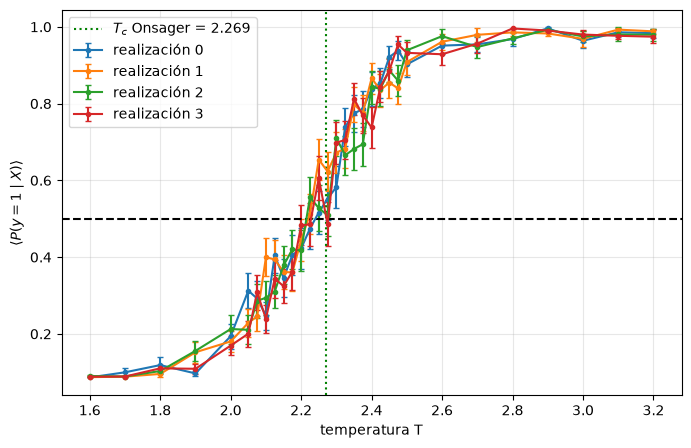

In [8]:
# --- Ejercicio 4 ---
df = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "prob": p1_tc})

resumen = (df.groupby(["realizacion", "T"])
             .agg(prob_media=("prob", "mean"),
                  prob_std=("prob", "std"),
                  N=("prob", "size"))
             .reset_index())

plt.figure(figsize=(8, 5))
for r, d in resumen.groupby("realizacion"):
    plt.errorbar(d["T"], d["prob_media"], yerr=d["prob_std"] / np.sqrt(d["N"]),
                 fmt="o-", ms=3, capsize=2, label=f"realización {r}")
plt.axhline(0.5, ls="--", color="k")
plt.axvline(Tc_exacto, ls=":", color="green", label=fr"$T_c$ Onsager = {Tc_exacto:.3f}")
plt.xlabel("temperatura T")
plt.ylabel(r"$\langle P(y=1\mid X)\rangle$")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Ejercicio 5 — Estimar $T_c$ por interpolación

Para cada realización, encuentra el primer par de temperaturas consecutivas donde
$\langle P\rangle$ cruza 0.5 e interpola linealmente:

$$T_c \approx T_i + (0.5 - P_i)\,\frac{T_{i+1}-T_i}{P_{i+1}-P_i}.$$

Luego promedia entre realizaciones y reporta la media, la desviación estándar y el error
estándar de la media (SEM).

In [9]:
# --- Ejercicio 5  ---
def cruce_05(temps, probs):
    temps, probs = np.asarray(temps), np.asarray(probs)
    for i in range(len(temps) - 1):
        if (probs[i] - 0.5) * (probs[i + 1] - 0.5) <= 0 and probs[i + 1] != probs[i]:
            return (temps[i] + (0.5 - probs[i]) *
                    (temps[i + 1] - temps[i]) / (probs[i + 1] - probs[i]))
    return np.nan

Tc_por_realizacion = []
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    Tc_r = cruce_05(d["T"].to_numpy(), d["prob_media"].to_numpy())
    Tc_por_realizacion.append(Tc_r)
    print(f"realización {r}:  Tc = {Tc_r:.4f}")

Tc_por_realizacion = np.array(Tc_por_realizacion)
Tc_est = np.nanmean(Tc_por_realizacion)
Tc_std = np.nanstd(Tc_por_realizacion, ddof=1)
Tc_sem = Tc_std / np.sqrt(np.sum(~np.isnan(Tc_por_realizacion)))

print("\n" + "-" * 44)
print(f"Tc estimado    = {Tc_est:.4f} +/- {Tc_sem:.4f} (SEM)")
print(f"Tc Onsager     = {Tc_exacto:.4f}")
print(f"error relativo = {100 * abs(Tc_est - Tc_exacto) / Tc_exacto:.2f} %")

realización 0:  Tc = 2.2403
realización 1:  Tc = 2.2204
realización 2:  Tc = 2.2149
realización 3:  Tc = 2.2280

--------------------------------------------
Tc estimado    = 2.2259 +/- 0.0055 (SEM)
Tc Onsager     = 2.2692
error relativo = 1.91 %


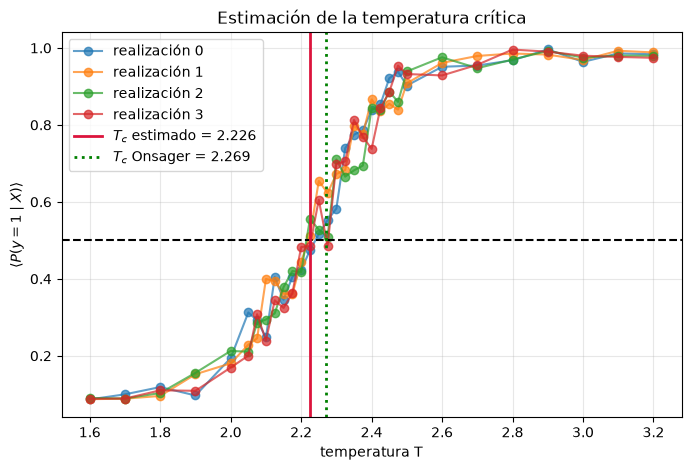

In [10]:
plt.figure(figsize=(8, 5))
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    plt.plot(d["T"], d["prob_media"], "o-", alpha=0.7, label=f"realización {r}")
plt.axhline(0.5, ls="--", color="k")
plt.axvline(Tc_est, ls="-", color="crimson", lw=2,
            label=fr"$T_c$ estimado = {Tc_est:.3f}")
plt.axvline(Tc_exacto, ls=":", color="green", lw=2,
            label=fr"$T_c$ Onsager = {Tc_exacto:.3f}")
plt.xlabel("temperatura T")
plt.ylabel(r"$\langle P(y=1\mid X)\rangle$")
plt.title("Estimación de la temperatura crítica")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Análisis crítico

Responde en celdas de texto, con evidencia (números o gráficas de tu notebook):

1. **Sesgo del estimador.** El $T_c$ estimado suele quedar *por debajo* de Onsager
   ($\approx 2.23$ vs $2.269$). Menciona al menos dos causas: tamaño finito $L=16$, definición
   de la etiqueta `y`, rango de temperaturas de entrenamiento, uso del umbral fijo 0.5.
2. **Arquitectura.** Repite el pipeline con `hidden_layer_sizes=(64,)` y con `(32, 16, 8)`.
   ¿Cambia $T_c$? ¿Cambia la *pendiente* de la curva en la transición?
3. **Reproducibilidad.** Entrena con 5 semillas distintas (`random_state`) y reporta
   $T_c$ media ± desviación. ¿La dispersión por semilla es mayor o menor que la dispersión
   entre realizaciones?
4. **Definición alternativa.** Usa la *fracción de configuraciones clasificadas como fase 1*
   (`pred.mean()` por $T$) en vez de `prob_media`. ¿Obtienes el mismo $T_c$?
5. **Estandarización.** Los espines ya están en $\{-1,+1\}$. ¿Ayuda un `StandardScaler`?
   ¿Por qué sí o por qué no en este problema?

In [11]:
def mlp(capas=(16, 8, 4), semilla=RNG):
    return MLPClassifier(hidden_layer_sizes=capas, activation="relu", solver="adam",
                         learning_rate_init=0.001, max_iter=1000, random_state=semilla)


def curvas(modelo, X_eval, T_eval, r_eval):
    """⟨P(y=1|X)⟩ y fracción de predicciones y = 1, por realización y temperatura."""
    p = modelo.predict_proba(X_eval)[:, list(modelo.classes_).index(1)]
    df = pd.DataFrame({"T": T_eval, "realizacion": r_eval, "prob": p, "pred": p >= 0.5})
    return df.groupby(["realizacion", "T"]).mean().reset_index()


def estimar_Tc(curva, col="prob"):
    """T_c (media y desviación entre realizaciones) y pendiente máxima dP/dT."""
    grupos = [g for _, g in curva.groupby("realizacion")]
    Tc = [cruce_05(g["T"], g[col]) for g in grupos]
    pendiente = [np.gradient(g[col], g["T"]).max() for g in grupos]
    return np.mean(Tc), np.std(Tc, ddof=1), np.mean(pendiente)


columnas = ["Tc", "std realizaciones", "pendiente máx."]

### 8.1 Sesgo del estimador

En este caso el sesgo no tiene un signo fijo. Con `random_state=42` (sección 5) se obtiene $T_c=2.226$, por debajo de Onsager, pero con otras semillas y arquitecturas el resultado queda por encima, entre 2.28 y 2.37 (secciones 8.2 y 8.3). Esto se puede explicar por varias causas.

Una es el rango de entrenamiento. No hay datos en $(1.9,\,2.6)$ y cualquier frontera dentro de ese intervalo separa perfectamente el conjunto de entrenamiento, de modo que el lugar donde termina la frontera lo deciden la inicialización y la arquitectura más que la física del problema.

A esto se suma el tamaño finito. Con $L=16$ la transición se suaviza: todavía en $T=2.4$ se tiene $\langle|m|\rangle\approx0.5$, y la curva tiene un ancho del orden de $1/\text{pendiente}\approx0.25$. El cruce puede caer en cualquier punto de esa ventana.

Por último están la etiqueta y el umbral. La etiqueta `y` se define por la temperatura y no por la configuración, y cerca de $T_c$ muchas configuraciones se parecen a las de la otra fase (la accuracy frente a `y_ref` es de solo 0.82). Además, el umbral de 0.5 es una convención.

### 8.2 Arquitectura

In [12]:
arq = {str(c): estimar_Tc(curvas(mlp(c).fit(X_train, y_train), X_tc, T_tc, realizacion_tc))
       for c in [(16, 8, 4), (64,), (32, 16, 8)]}
pd.DataFrame(arq, index=columnas).T.round(3)

,Tc,std realizaciones,pendiente máx.
"(16, 8, 4)",2.226,0.011,4.017
"(64,)",2.374,0.026,4.217
"(32, 16, 8)",2.365,0.013,4.441


Al cambiar la arquitectura, $T_c$ se mueve entre 2.23 y 2.37, mientras que la pendiente máxima casi no cambia (entre 4.0 y 4.4). Esto indica que el ancho de la transición lo fija el tamaño finito del sistema y que la posición del cruce depende más bien del clasificador.

### 8.3 Reproducibilidad

In [13]:
sem = pd.DataFrame({s: estimar_Tc(curvas(mlp(semilla=s).fit(X_train, y_train), X_tc, T_tc, realizacion_tc))
                    for s in range(5)}, index=columnas).T
print(f"Tc entre semillas: {sem['Tc'].mean():.3f} ± {sem['Tc'].std():.3f}")
print(f"desviación media entre realizaciones: {sem['std realizaciones'].mean():.3f}")
sem.round(3)

Tc entre semillas: 2.344 ± 0.037
desviación media entre realizaciones: 0.022


,Tc,std realizaciones,pendiente máx.
0,2.358,0.015,4.284
1,2.363,0.022,4.709
2,2.362,0.022,4.386
3,2.277,0.029,5.022
4,2.358,0.023,4.580


La dispersión por semilla (0.037) es mayor que la dispersión entre realizaciones (0.022). Es decir, la mayor parte de la incertidumbre en $T_c$ sale del entrenamiento y no de la estadística de Monte Carlo. La semilla 42 de la sección 5 resulta ser la excepción, ya que con las semillas 0 a 4 el $T_c$ queda por encima de Onsager.

### 8.4 Definición alternativa

In [14]:
curva = curvas(model, X_tc, T_tc, realizacion_tc)
for col, nombre in [("prob", "prob_media"), ("pred", "fracción y = 1")]:
    Tc_c, std_c, pend_c = estimar_Tc(curva, col)
    print(f"{nombre:15s}: Tc = {Tc_c:.4f} ± {std_c:.4f},  pendiente máx. = {pend_c:.2f}")

prob_media     : Tc = 2.2259 ± 0.0110,  pendiente máx. = 4.02
fracción y = 1 : Tc = 2.2331 ± 0.0134,  pendiente máx. = 5.20


Se obtiene prácticamente el mismo valor, 2.233 frente a 2.226, y la diferencia es menor que la dispersión entre realizaciones. La fracción de predicciones es una versión escalonada de la misma curva, por eso su pendiente máxima sale mayor (5.2 frente a 4.0).

### 8.5 Estandarización

In [15]:
print(f"media por píxel: [{X_train.mean(0).min():.3f}, {X_train.mean(0).max():.3f}],  "
      f"desviación por píxel: [{X_train.std(0).min():.3f}, {X_train.std(0).max():.3f}]")

escalado = make_pipeline(StandardScaler(), mlp()).fit(X_train, y_train)
Tc_e, std_e, _ = estimar_Tc(curvas(escalado, X_tc, T_tc, realizacion_tc))
print(f"accuracy test: {escalado.score(X_test, y_test):.4f}  (sin escalar: {model.score(X_test, y_test):.4f})")
print(f"Tc con StandardScaler: {Tc_e:.4f} ± {std_e:.4f}")

media por píxel: [-0.037, 0.125],  desviación por píxel: [0.992, 1.000]


accuracy test: 0.9900  (sin escalar: 0.9875)
Tc con StandardScaler: 2.2076 ± 0.0083


No ayuda. La media por píxel ya es cercana a 0 porque la fase ordenada aparece con los dos signos de $m$ (simetría $Z_2$), y la desviación ya es cercana a 1 porque los espines valen $\pm1$. Entonces `StandardScaler` es casi la identidad. En efecto, la accuracy cambia en un solo ejemplo de test y $T_c$ se mueve 0.02, lo cual está dentro de la dispersión por semilla.

## 9. Reto  — Escalamiento con el tamaño del sistema

Con el programa de ising generar varias datos para diferentes tipo de redes L=10x10, L=15x15, L=20x20, L=25x25, L=30x30

1. Construye un conjunto de entrenamiento.
2. Entrena un nuevo `MLPClassifier`, repite los Ejercicios 4–5 y obtén $T_c(L=20)$.
3. Compara todas las $T_c$ ¿La estimación se acerca a Onsager al crecer $L$?
   Relaciónalo con el *finite-size scaling*.

In [16]:
def metropolis(L, temps, n_cadenas, n_muestras, rng, termalizacion=2000, separacion=10):
    """Configuraciones de Ising 2D (J = k_B = 1, frontera periódica) con Metropolis por subredes.
    Simula en paralelo todas las temperaturas y cadenas; cada cadena parte de un estado ordenado
    de signo aleatorio. Devuelve un arreglo de forma (n_T, n_cadenas, n_muestras, L, L)."""
    g = np.arange(L) % 2
    if L % 2:  # con L impar la frontera periódica necesita un tercer color
        g[-1] = 2
    color = (g[:, None] + g[None, :]) % 3  # dos vecinos nunca comparten color
    beta = 1 / np.asarray(temps)[:, None, None, None]
    s = rng.choice([-1, 1], size=(len(temps), n_cadenas, 1, 1)).astype(np.int8) * np.ones((L, L), np.int8)
    muestras = []
    for barrido in range(termalizacion + n_muestras * separacion):
        for c in range(color.max() + 1):
            vecinos = np.roll(s, 1, -1) + np.roll(s, -1, -1) + np.roll(s, 1, -2) + np.roll(s, -1, -2)
            acepta = (color == c) & (rng.random(s.shape) < np.exp(-2 * beta * s * vecinos))
            s = np.where(acepta, -s, s)
        if barrido >= termalizacion and (barrido - termalizacion + 1) % separacion == 0:
            muestras.append(s)
    return np.stack(muestras, axis=2)

In [17]:
T_entr = np.unique(T)     # temperaturas de ising_dataset.npz
T_barr = np.unique(T_tc)  # temperaturas de temperatura_critica.npz
rng_mc = np.random.default_rng(0)

modelos, curvas_L, Tc_L = {}, {}, {}
for lado in [10, 15, 20, 25, 30]:
    # 1. Entrenamiento: 2 cadenas x 40 configuraciones por temperatura, como train en ising_dataset
    X_e = metropolis(lado, T_entr, 2, 40, rng_mc).reshape(-1, lado * lado)
    y_e = np.repeat(T_entr > Tc_exacto, 2 * 40).astype(int)
    # Barrido fino: 4 realizaciones x 50 configuraciones por temperatura
    X_b = metropolis(lado, T_barr, 4, 50, rng_mc).reshape(-1, lado * lado)
    T_b = np.repeat(T_barr, 4 * 50)
    r_b = np.tile(np.repeat(np.arange(4), 50), len(T_barr))
    # 2. Un MLP por semilla; Tc por cruce con 0.5 (Ejercicios 4-5)
    modelos[lado] = [mlp(semilla=s).set_params(max_iter=3000).fit(X_e, y_e) for s in range(5)]
    curvas_L[lado] = curvas(modelos[lado][0], X_b, T_b, r_b)
    Tc_L[lado] = [estimar_Tc(curvas(mdl, X_b, T_b, r_b))[0] for mdl in modelos[lado]]
    print(f"L = {lado}:  Tc = {np.mean(Tc_L[lado]):.3f} ± {np.std(Tc_L[lado], ddof=1):.3f}  (5 semillas)")

L = 10:  Tc = 2.318 ± 0.014  (5 semillas)


L = 15:  Tc = 2.331 ± 0.049  (5 semillas)


L = 20:  Tc = 2.329 ± 0.071  (5 semillas)


L = 25:  Tc = 2.353 ± 0.074  (5 semillas)


L = 30:  Tc = 2.347 ± 0.044  (5 semillas)


Tc(L = 20) en temperatura_critica20.npz: 2.336 ± 0.076


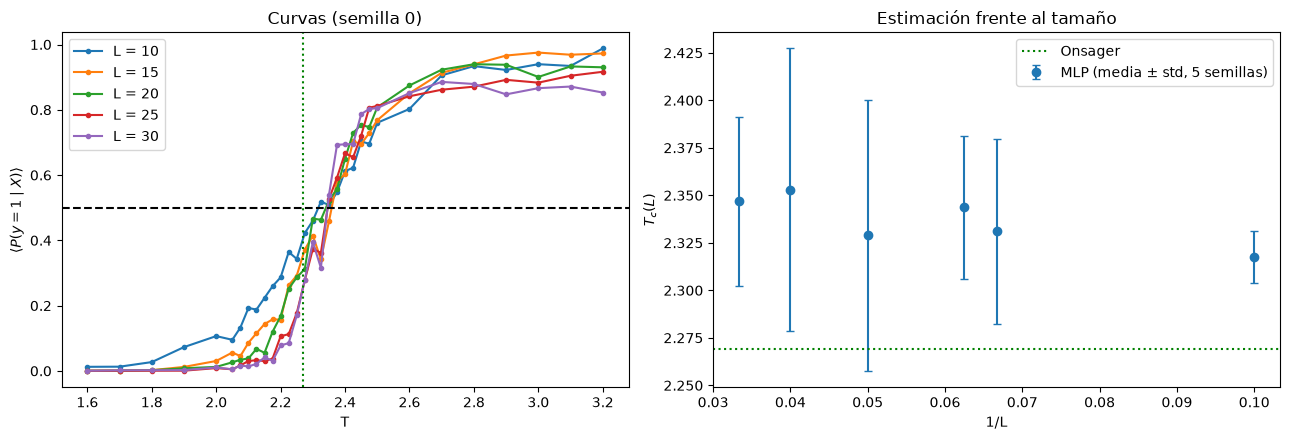

In [18]:
# Tc(L = 20) sobre el barrido provisto, con los mismos modelos
datos_tc20 = np.load("Datos/temperatura_critica20.npz", allow_pickle=False)
X20 = datos_tc20["X"].reshape(len(datos_tc20["X"]), -1)
Tc20 = [estimar_Tc(curvas(mdl, X20, datos_tc20["T"], datos_tc20["realizacion"]))[0] for mdl in modelos[20]]
print(f"Tc(L = 20) en temperatura_critica20.npz: {np.mean(Tc20):.3f} ± {np.std(Tc20, ddof=1):.3f}")

Tc_L[16] = list(sem["Tc"])  # 5 semillas de la sección 8.3
lados = np.array(sorted(Tc_L))
medias = np.array([np.mean(Tc_L[l]) for l in lados])
errores = np.array([np.std(Tc_L[l], ddof=1) for l in lados])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for lado, c in curvas_L.items():
    p = c.groupby("T")["prob"].mean()
    axes[0].plot(p.index, p.values, "o-", ms=3, label=f"L = {lado}")
axes[0].axhline(0.5, ls="--", color="k")
axes[0].axvline(Tc_exacto, ls=":", color="green")
axes[0].set(xlabel="T", ylabel=r"$\langle P(y=1\mid X)\rangle$", title="Curvas (semilla 0)")
axes[0].legend()
axes[1].errorbar(1 / lados, medias, yerr=errores, fmt="o", capsize=3, label="MLP (media ± std, 5 semillas)")
axes[1].axhline(Tc_exacto, ls=":", color="green", label="Onsager")
axes[1].set(xlabel="1/L", ylabel="$T_c(L)$", title="Estimación frente al tamaño")
axes[1].legend()
plt.tight_layout()
plt.show()

Para todos los tamaños se obtiene $T_c(L)\approx2.32$–$2.35$, con una dispersión por semilla entre 0.01 y 0.07. Con $L=20$ el barrido provisto da el mismo valor que el generado aquí (2.336 frente a 2.329), lo que sirve como validación del generador.

La estimación no se acerca a Onsager al crecer $L$. Las curvas se vuelven más abruptas del lado ordenado, pero el cruce no se desplaza hacia 2.269. El *finite-size scaling* predice $T_c(L)-T_c\propto L^{-1/\nu}$, con $\nu=1$, para temperaturas pseudocríticas ligadas a la longitud de correlación, como el máximo de la susceptibilidad. El cruce del clasificador no es una de esas temperaturas. Como el entrenamiento excluye el intervalo $(1.9,\,2.6)$, la posición de la frontera la fija el clasificador (sección 8), y por eso no hereda ese escalamiento.